# 1. Reguły i metryki podobieństwa

Regex, odległość Levenshteina, Jaro–Winkler i indeks Jaccarda jako lokalne baseline’y filtra antyphishingowego.

## Protokół wspólny

Dane lokalne: pełny `combined_reduced.json` (77 677 rekordów, `1` = phishing,
`0` = benign); mieszanina URL, SMS, e-maili i HTML, a nie tylko e-maile.
Każdy notatnik sprawdza SHA-256 wszystkich części i oryginału.
Po odrzuceniu pustych wejść, konfliktów etykiet i duplikatów znormalizowanych
pierwszych 4000 znaków wybieramy warstwowo **8000 rekordów** z ziarnem 42.
Używamy tego samego podziału train/validation/test = **60/20/20**.
To demonstracja na próbce; pełny zbiór pozostaje w `data`.

Wszystkie reprezentacje uczymy tylko na train. Walidacja służy do wyboru progu
w metodach nadzorowanych; test zostaje na końcowy pomiar. Zbiory są rozłączne
po kluczu normalizacji, lecz bliskie duplikaty lub rodziny kampanii nadal mogą
przeciekać: brak dat i identyfikatorów kampanii uniemożliwia wiarygodny test czasowy.
Nie odwiedzamy linków ani nie renderujemy HTML. Nie korzystamy z API modeli,
internetu podczas wykonania ani pobieranych modeli językowych.

Czasy to pomiar CPU w tej maszynie, z mediany 3 wywołań po rozgrzewce, w ms/próbkę
w batchu testowym (nie opóźnienie pojedynczego żądania). Obejmują transformację tekstu,
ale nie odczyt plików. Rozmiar to nieskompresowana serializacja pickle obiektu
potrzebnego do predykcji, bez środowiska Pythona i danych. Wartości między rodzinami
zadań nie są automatycznie porównywalne. Czułość = recall klasy phishing;
FPR = FP / (FP + TN). Average precision podsumowuje ranking precision–recall.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Uruchomienie z katalogu repozytorium albo z notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'notebooks' / 'common.py').exists())
sys.path.insert(0, str(ROOT / 'notebooks'))
from common import (SEED, load_splits, classification_metrics, choose_threshold,
                    timed_prediction, size_mib, save_results)
train, validation, test = load_splits()
y_train = train.label.to_numpy()
y_val = validation.label.to_numpy()
y_test = test.label.to_numpy()
x_train = train.input.tolist()
x_val = validation.input.tolist()
x_test = test.input.tolist()
display(pd.DataFrame({'train': train.label.value_counts(),
                      'validation': validation.label.value_counts(),
                      'test': test.label.value_counts()}).rename_axis('label'))

{
  "source_records": 77677,
  "deduplicated_sample": 8000,
  "conflicting_keys_removed": 3,
  "seed": 42,
  "train": 4800,
  "validation": 1600,
  "test": 1600,
  "max_input_chars": 4000,
  "split_sha256": {
    "train": "dbd41bff6349f412f1cbc777e2a7e19e75f23d09586914fd0518a620cd0caf18",
    "validation": "5ef4b8c140c03e6f97c2a792e2887a785aac5d59986fd08ea41784e87d85904b",
    "test": "ce29c3a3e537a8f6d97ad38fd43fe2c5952ff6ed04c7611991a05c8784e0aa5c"
  }
}


,train,validation,test
label,,,
0,2802,934,934
1,1998,666,666


## Diagram przebiegu analizy

Poniższy schemat pokazuje rolę danych i etapy eksperymentu. Diagramy i wykresy są generowane lokalnie i osadzane w notatniku jako PNG.

Fontconfig error: No writable cache directories


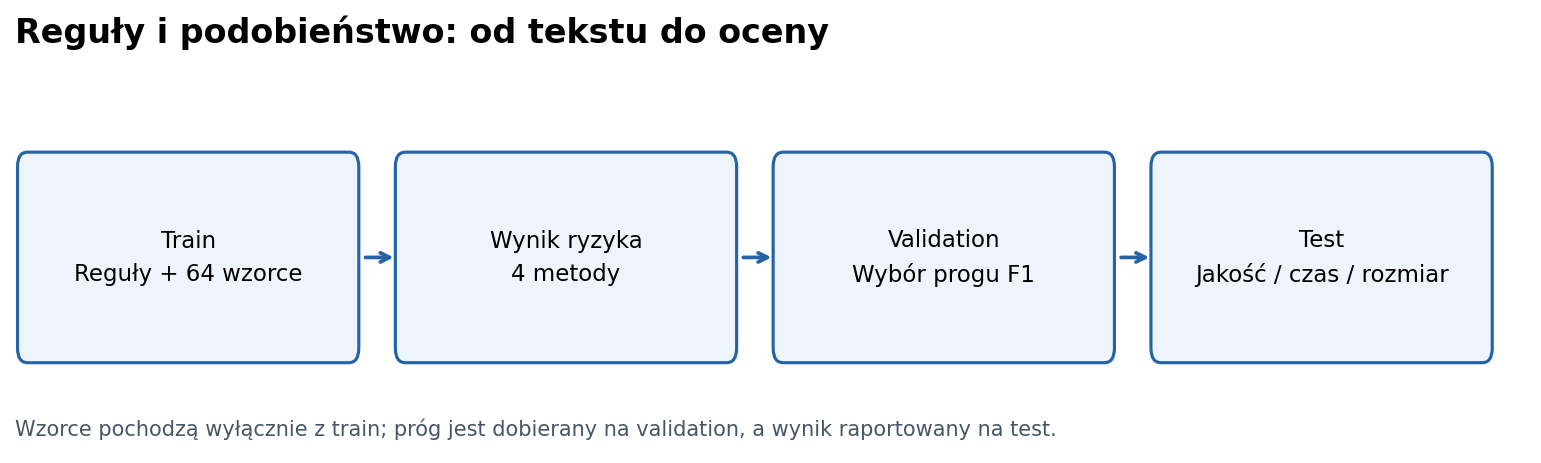

In [2]:
from visuals import workflow, metric_bars, heatmap_grid, render, plt
workflow('Reguły i podobieństwo: od tekstu do oceny', ['Train\nReguły + 64 wzorce', 'Wynik ryzyka\n4 metody', 'Validation\nWybór progu F1', 'Test\nJakość / czas / rozmiar'], 'Wzorce pochodzą wyłącznie z train; próg jest dobierany na validation, a wynik raportowany na test.')

## Regex: ustalone reguły

Sygnały: presja czasu, konto/hasło, wezwanie do działania, oferta/nagroda,
adres IP w URL i kodowanie procentowe. Suma trafień jest wynikiem ryzyka;
sam URL ani HTTPS nie rozstrzygają o phishingu. Reguły są ustalone przed oceną,
nie dobieramy ich po obejrzeniu testu. Angielskie słowa pasują do języka źródła,
ale mogą zawodzić w innych językach i przy parafrazie.

In [3]:
import re
PATTERNS = [
    r'\b(?:urgent|immediately|suspended|expire[sd]?|limited time)\b',
    r'\b(?:password|credential|account|login|log in)\b',
    r'\b(?:verify|confirm|click|update|sign in)\b',
    r'\b(?:winner|prize|lottery|free money|reward)\b',
    r'https?://(?:\d{1,3}\.){3}\d{1,3}(?:[:/]|$)',
    r'https?://\S*%[0-9a-f]{2}',
]
rules = [re.compile(p, re.I) for p in PATTERNS]
def regex_scores(texts):
    return np.array([sum(bool(r.search(t)) for r in rules) for t in texts], dtype=float)
rows = []
start = perf_counter()
regex_threshold = choose_threshold(y_val, regex_scores(x_val))
regex_fit_s = perf_counter() - start
scores, latency = timed_prediction(regex_scores, x_test)
rows.append(dict(method='Regex', threshold=regex_threshold, fit_s=regex_fit_s,
                 ms_per_sample=latency, model_mib=size_mib((PATTERNS, regex_threshold)),
                 **classification_metrics(y_test, scores >= regex_threshold, scores)))
display(pd.DataFrame(rows).round(4))

,method,threshold,fit_s,ms_per_sample,model_mib,accuracy,precision,recall,f1,fpr,roc_auc,average_precision,tn,fp,fn,tp
0,Regex,0.0,0.2246,0.0941,0.0004,0.4162,0.4162,1.0,0.5878,1.0,0.565,0.4717,0,934,0,666


## Levenshtein, Jaro–Winkler i Jaccard

- Levenshtein: minimalna liczba wstawień/usunięć/zamian; używamy podobieństwa
  `1 − distance/max(len(a),len(b))` z RapidFuzz.
- Jaro–Winkler: podobieństwo znakowe z premią za wspólny prefiks.
- Jaccard: `|A ∩ B| / |A ∪ B|` na zbiorach tokenów, bez uwzględniania kolejności.

Wzorce: 32 losowe przykłady **z każdej klasy train** (seed 42).
Tekst normalizujemy do lowercase, pojedynczych spacji i pierwszych 600 znaków.
Usuwamy kolizje po tej dodatkowej normalizacji między pulą wzorców a validation/test
(bez patrzenia na ich etykiety), aby nie otrzymać sztucznych trafień 1:1.
Wynik ryzyka = największe podobieństwo do wzorca phishing − największe podobieństwo
do wzorca benign. To klasyfikacja ze znanymi etykietami wzorców, a nie metoda
bez nadzoru. Progi maksymalizują F1 na validation; to nie gwarantuje niskiego FPR.

In [4]:
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein, JaroWinkler
def normalize(s):
    return re.sub(r'\s+', ' ', s.lower()).strip()[:600]
heldout = {normalize(t) for t in x_val + x_test}
pool = train.copy()
pool['normalized'] = pool.input.map(normalize)
pool = pool[~pool.normalized.isin(heldout)].drop_duplicates('normalized')
templates = pd.concat([pool[pool.label == c].sample(32, random_state=SEED)
                       for c in [0, 1]], ignore_index=True)
references = templates.normalized.tolist()
ref_labels = templates.label.to_numpy()
token_pattern = re.compile(r'[a-z0-9]+')
reference_sets = [set(token_pattern.findall(s)) for s in references]

def similarity_scores(texts, method):
    query = [normalize(t) for t in texts]
    if method == 'Jaccard':
        sets = [set(token_pattern.findall(s)) for s in query]
        similarities = np.array([[len(a & b) / max(1, len(a | b))
                                   for b in reference_sets] for a in sets])
    else:
        scorer = {'Levenshtein': Levenshtein.normalized_similarity,
                  'Jaro-Winkler': JaroWinkler.normalized_similarity}[method]
        similarities = process.cdist(query, references, scorer=scorer,
                                     workers=1, dtype=np.float32)
    return similarities[:, ref_labels == 1].max(axis=1) - similarities[:, ref_labels == 0].max(axis=1)

for method in ['Levenshtein', 'Jaro-Winkler', 'Jaccard']:
    start = perf_counter()
    threshold = choose_threshold(y_val, similarity_scores(x_val, method))
    fit_s = perf_counter() - start
    predict = lambda texts, m=method: similarity_scores(texts, m)
    scores, latency = timed_prediction(predict, x_test)
    rows.append(dict(method=method, threshold=threshold, fit_s=fit_s,
                     ms_per_sample=latency,
                     model_mib=size_mib((references, ref_labels, threshold, method)),
                     **classification_metrics(y_test, scores >= threshold, scores)))
assert len(rows) == 4

## Łączne podsumowanie porównawcze

Poniżej wszystkie cztery rozwiązania na tych samych próbkach testowych.
`fit_s` oznacza tutaj kalibrację progu z obliczeniem wyników walidacyjnych;
nie obejmuje odczytu danych i wspólnego wyboru wzorców.
Model metryk obejmuje teksty wzorców, etykiety i próg, a regex wzorce i próg.

In [5]:
summary = save_results('01_reguly_i_metryki', rows)
display(summary.sort_values('f1', ascending=False).round(4))
best = summary.loc[summary.f1.idxmax()]
fastest = summary.loc[summary.ms_per_sample.idxmin()]
display(Markdown(f"Najwyższe zaobserwowane F1: **{best['method']}** ({best.f1:.3f}); "
                 f"czułość {best.recall:.3f}, FPR {best.fpr:.3f}. "
                 f"Najkrótszy czas w tym pomiarze: **{fastest['method']}**. "
                 "To opis testu, nie wybór kolejnego progu na teście."))

,method,threshold,fit_s,ms_per_sample,model_mib,accuracy,precision,recall,f1,fpr,roc_auc,average_precision,tn,fp,fn,tp
1,Levenshtein,-0.0167,0.4457,0.2142,0.0128,0.5925,0.5061,0.8664,0.6390,0.6028,0.7323,0.6772,371,563,89,577
3,Jaccard,-0.0179,0.3020,0.1304,0.0128,0.5131,0.4584,0.9339,0.6149,0.7869,0.6617,0.5877,199,735,44,622
2,Jaro-Winkler,-0.0150,0.3797,0.1709,0.0128,0.5644,0.4862,0.8213,0.6108,0.6188,0.6666,0.5808,356,578,119,547
0,Regex,0.0000,0.2246,0.0941,0.0004,0.4162,0.4162,1.0000,0.5878,1.0000,0.5650,0.4717,0,934,0,666


Najwyższe zaobserwowane F1: **Levenshtein** (0.639); czułość 0.866, FPR 0.603. Najkrótszy czas w tym pomiarze: **Regex**. To opis testu, nie wybór kolejnego progu na teście.

## Diagramy porównawcze wyników

Pierwszy wykres zestawia F1, czułość i FPR na teście przy progach dobranych na
walidacji. Strzałka ↑ oznacza „więcej = lepiej”, ↓ „mniej = lepiej”. Wysoka
czułość regex przy jednocześnie wysokim FPR nie oznacza skutecznego filtra.
Drugie zestawienie pokazuje koszt: obie osie czasu/rozmiaru są logarytmiczne,
a etykiety podają wartości w oryginalnych jednostkach. Czas obejmuje transformację
wejścia i predykcję, bez odczytu danych; rozmiar jest oszacowaniem pickle.

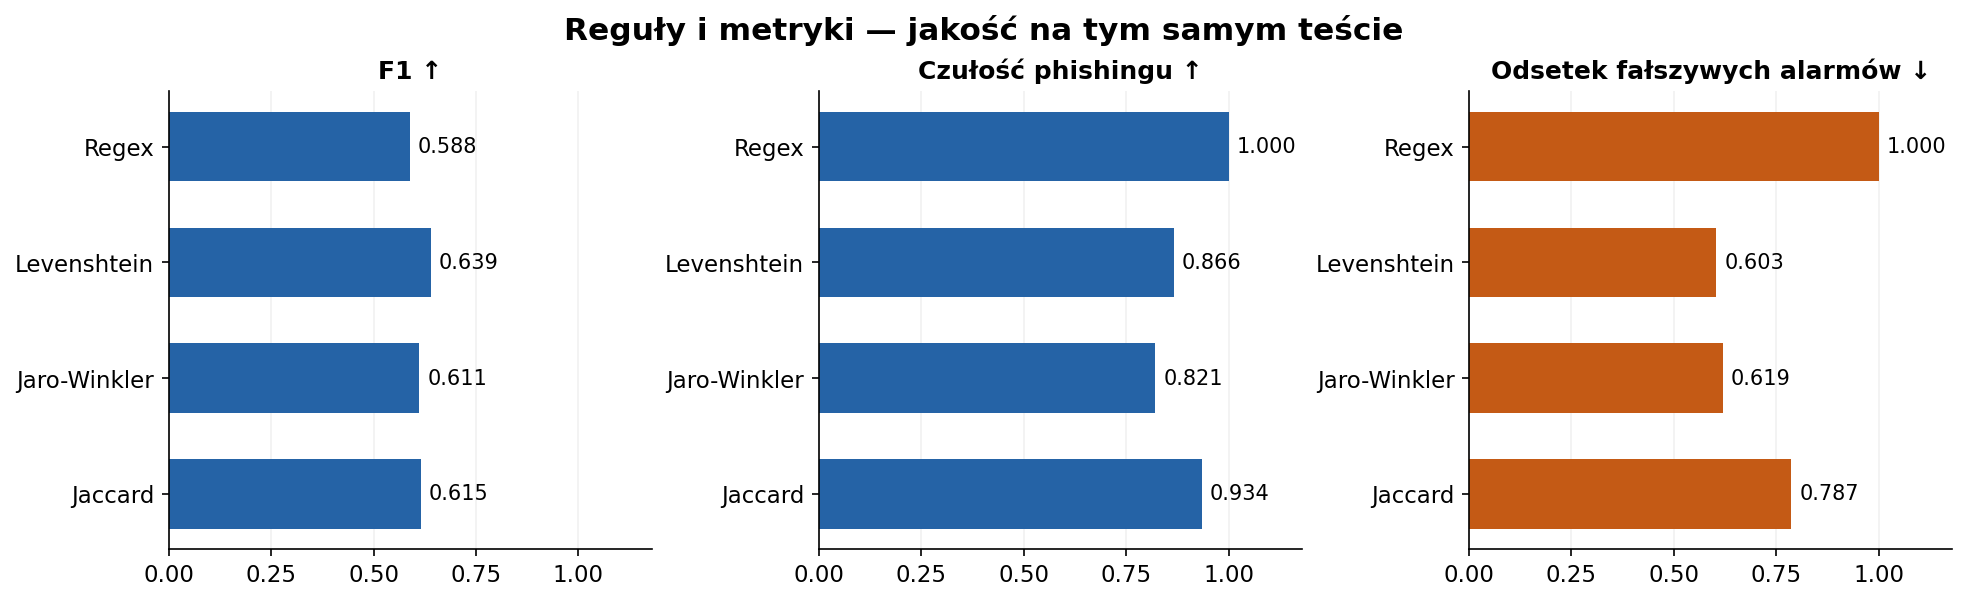

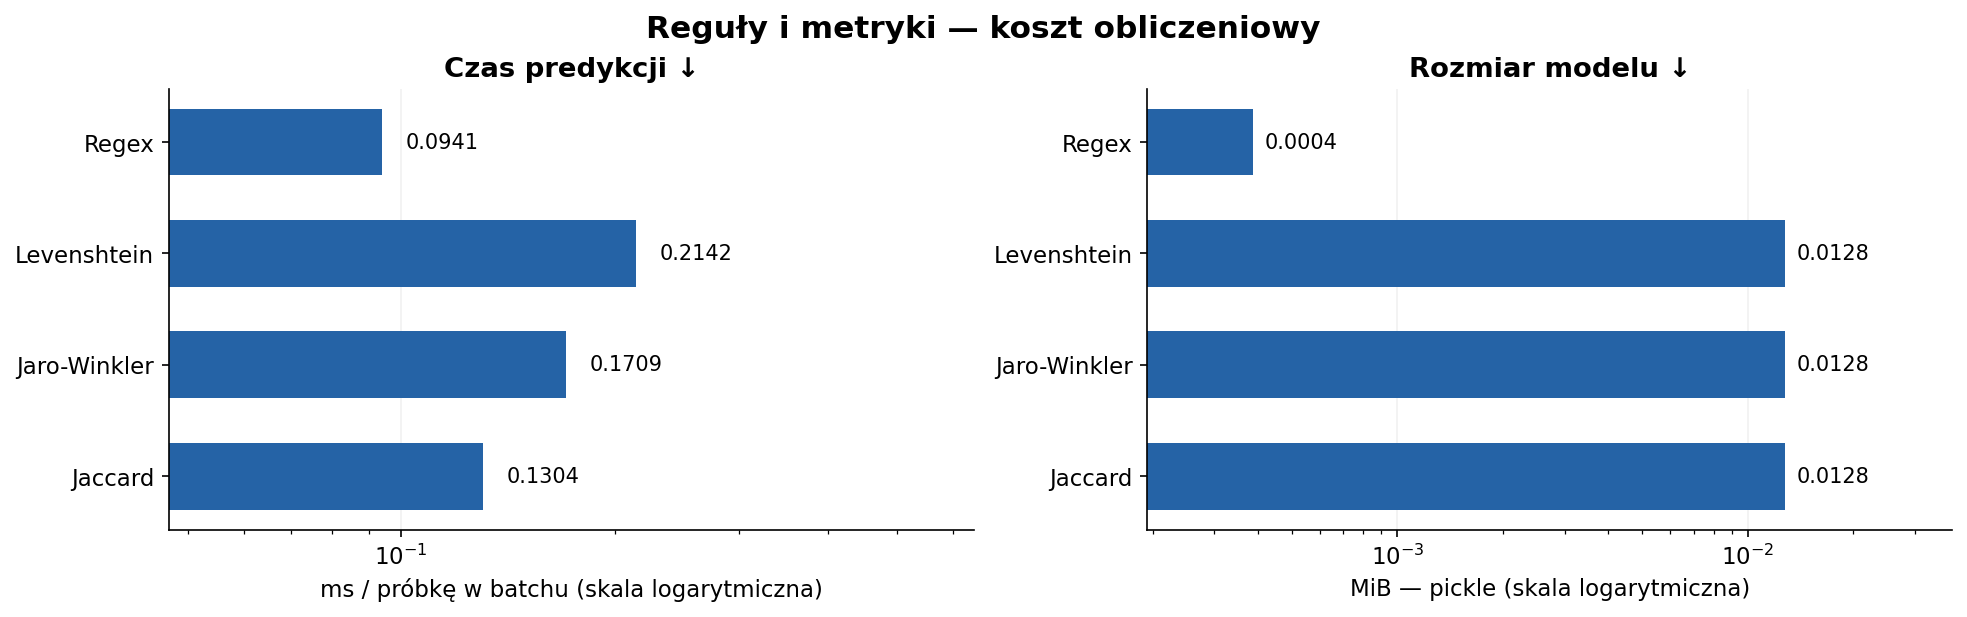

In [6]:
metric_bars(summary, [('f1', 'F1', False), ('recall', 'Czułość phishingu', False),
                      ('fpr', 'Odsetek fałszywych alarmów', True)],
            'Reguły i metryki — jakość na tym samym teście')
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, column, title, unit in [
    (axes[0], 'ms_per_sample', 'Czas predykcji ↓', 'ms / próbkę w batchu'),
    (axes[1], 'model_mib', 'Rozmiar modelu ↓', 'MiB — pickle')]:
    values = summary[column].to_numpy()
    ax.barh(summary.method, values, color='#2563a6', height=.6)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlim(values.min() / 2, values.max() * 3)
    ax.set_title(title)
    ax.set_xlabel(unit + ' (skala logarytmiczna)')
    ax.grid(axis='x', alpha=.18)
    ax.set_axisbelow(True)
    for i, value in enumerate(values):
        ax.text(value * 1.08, i, f'{value:.4f}', va='center', fontsize=10)
fig.suptitle('Reguły i metryki — koszt obliczeniowy', fontweight='bold', fontsize=15)
render(fig)

**Wnioski i ograniczenia:** regex jest mały i łatwy do audytu, ale podatny na zmianę
słownictwa. Odległości znakowe wykrywają literówki i warianty znanych szablonów;
Jaro–Winkler może nadmiernie premiować wspólne prefiksy. Jaccard toleruje
przestawianie słów, lecz ignoruje składnię i negację. Wszystkie metody wzorcowe
zależą od reprezentatywności 64 przykładów; nie dowodzą rozumienia intencji.
Rozszerzanie bazy wzorców zwiększa czas predykcji. Przed wdrożeniem należy dobrać
próg do kosztu fałszywego alarmu na osobnej walidacji i użyć testu czasowego.

W zapisanym wykonaniu regex ma recall=1 i FPR=1: walidacyjne maksimum F1
wybrało próg, który przepuszcza każdą wiadomość do klasy phishing. To bezużyteczny
filtr operacyjny pomimo pozornie przyzwoitego F1; sam recall lub F1 nie wystarcza
bez FPR i precision. Dalszy rozwój wymaga silniejszych reguł lub doboru progu
z ograniczeniem FPR, ocenianych na nowej walidacji.